This Notebook was used to also download and prepare the further datasets, which might not have an original embedding given. 

In [ ]:
import warnings

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc
import scvelo
from tqdm import tqdm

warnings.filterwarnings('ignore')

AnnData object with n_obs × n_vars = 5422 × 11848
    obs: 'Plate_Id', 'Condition_Id', 'Well_Id', 'RFP_log10_corrected', 'GFP_log10_corrected', 'Cell_cycle_possition', 'Cell_cycle_relativePos', 'exp_type', 'time'
    var: 'Gene_Id'
    layers: 'sl', 'su', 'ul', 'uu'
Normalized count data: X, spliced, unspliced.
Extracted 2000 highly variable genes.
Logarithmized X.


/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/site-packages/scvelo/preprocessing/utils.py:705: DeprecationWarning: `log1p` is deprecated since scVelo v0.3.0 and will be removed in a future version. Please use `log1p` from `scanpy.pp` instead.
  log1p(adata)
/tmp/ipykernel_573681/2023376512.py:10: DeprecationWarning: Automatic neighbor calculation is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors first with Scanpy.
  scvelo.pp.moments(adata, n_pcs=30, n_neighbors=30)
/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/site-packages/scvelo/preprocessing/moments.py:71: DeprecationWarning: `neighbors` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors with Scanpy.
  neighbors(
/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/site-packages/scvelo/preprocessing/neighbors.py:233: DeprecationWarning: Automatic computation o

computing neighbors
    finished (0:00:14) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:01) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
recovering dynamics (using 1/28 cores)


  0%|          | 0/451 [00:00<?, ?gene/s]

    finished (0:05:56) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
computing velocities
    finished (0:00:02) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/28 cores)


  0%|          | 0/5422 [00:00<?, ?cells/s]

    finished (0:00:06) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:00) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


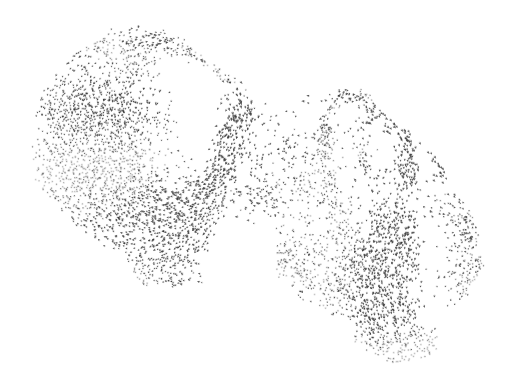

computing velocity embedding
    finished (0:00:00) --> added
    'velocity_tsne', embedded velocity vectors (adata.obsm)


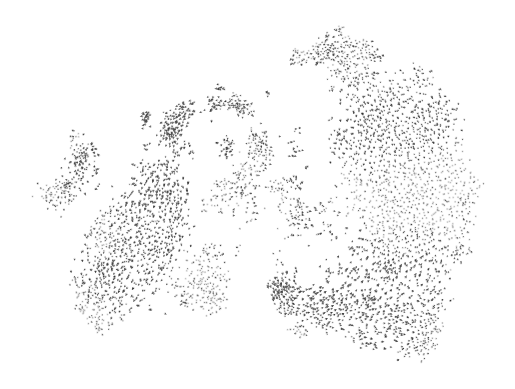

computing velocity embedding
    finished (0:00:00) --> added
    'velocity_pca', embedded velocity vectors (adata.obsm)


In [2]:
# Dataset 10 - Cell-cycle Data
# Download: https://www.dropbox.com/scl/fi/f9zwinj5h01uwpdkne1fz/?rlkey=5wggh79xos95b1e95pi0f7dbn&e=3
adata = sc.read("../data/noEmbedding/rpe1.h5ad")
print(adata)
adata.layers['spliced'] = adata.layers['sl'] + adata.layers['su']
adata.layers['unspliced'] = adata.layers['ul'] + adata.layers['uu']
adata.uns['exp_type_color'] = ['#0072b2', "#26e600"]

scvelo.pp.filter_and_normalize(adata, n_top_genes=2000)
scvelo.pp.moments(adata, n_pcs=30, n_neighbors=30)
scvelo.tl.recover_dynamics(adata, n_jobs=1)
scvelo.tl.velocity(adata, mode='dynamical')
scvelo.tl.velocity_graph(adata) 
sc.tl.umap(adata)
scvelo.pl.velocity_embedding(adata, basis='umap')
sc.tl.tsne(adata)
scvelo.pl.velocity_embedding(adata, basis='tsne')
scvelo.tl.velocity_embedding(adata, basis='pca')
adata.write_h5ad("../data/noEmbedding/intestinal_organoids_precomputed.h5ad")

In [ ]:
# Dataset 11 - Mouse hindbrain
# Download: https://figshare.com/articles/dataset/DeepVelo_processed_hindbrain_development_and_mesenchymal_chondrocyte_organogenesis_data/24716592?file=43428348
adata = sc.read("../data/noEmbedding/Hindbrain_GABA_Glio.h5ad")
print(adata)
scvelo.pp.filter_and_normalize(adata, n_top_genes=2000)
scvelo.pp.moments(adata, n_pcs=30, n_neighbors=30)
scvelo.tl.recover_dynamics(adata, n_jobs=1)
scvelo.tl.velocity(adata, mode='dynamical')
scvelo.tl.velocity_graph(adata) 
scvelo.tl.velocity_embedding(adata, basis='tsne')
scvelo.tl.velocity_embedding(adata, basis='pca')
sc.tl.umap(adata)
scvelo.tl.velocity_embedding(adata, basis='umap')

adata.uns['Celltype_colors'] = ['#0072b2', '#e69f00', '#d55e00', '#f0e442', '#000000', '#56b4e9']
adata.write_h5ad("../data/noEmbedding/hindbrain_precomputed.h5ad")

AnnData object with n_obs × n_vars = 13501 × 55421
    obs: 'TotalUMIs', 'barcode', 'Celltype', 'Lineage', 'Timepoint'
    var: 'Accession', 'AccessionVersion', 'Aliases', 'CcdsID', 'Chromosome', 'ChromosomeEnd', 'ChromosomeStart', 'CosmicID', 'DnaBindingDomain', 'FullName', 'GeneType', 'HgncID', 'IsTFi (TcoF-DB)', 'Location', 'LocationSortable', 'LocusGroup', 'LocusType', 'MgdID', 'MirBaseID', 'OmimID', 'PubmedID', 'RefseqID', 'Regulates (TRRUST)', 'RgdID', 'Strand', 'UcscID', 'UniprotID', 'VegaID'
    obsm: 'X_tsne'
    layers: 'matrix', 'spliced', 'unspliced'
Normalized count data: X, spliced, unspliced.
Extracted 2000 highly variable genes.
Logarithmized X.


/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/site-packages/scvelo/preprocessing/utils.py:705: DeprecationWarning: `log1p` is deprecated since scVelo v0.3.0 and will be removed in a future version. Please use `log1p` from `scanpy.pp` instead.
  log1p(adata)
/tmp/ipykernel_270216/1481730497.py:5: DeprecationWarning: Automatic neighbor calculation is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors first with Scanpy.
  scvelo.pp.moments(adata, n_pcs=30, n_neighbors=30)
/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/site-packages/scvelo/preprocessing/moments.py:71: DeprecationWarning: `neighbors` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors with Scanpy.
  neighbors(
/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/site-packages/scvelo/preprocessing/neighbors.py:233: DeprecationWarning: Automatic computation of

computing neighbors
    finished (0:00:40) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
recovering dynamics (using 1/28 cores)
or disable the progress bar using `show_progress_bar=False`.
    finished (0:16:41) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
computing velocities
    finished (0:00:06) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/28 cores)
    finished (0:00:12) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:02) --> added
    'velocity_tsne', embedded velocity vectors (adata.obsm)
computing velocity embedding
    finished (0:00:02) --> added
    'velocity_pca', embedded velocity vectors (adata.obsm)


In [ ]:
# Dataset 12 - Mouse Oligodendrcyte differentiation
# Download: https://pklab.med.harvard.edu/ruslan/velocity/oligos/
adata = sc.read("../data/noEmbedding/OligoPons_metafromSten.loom")
print(adata)
adata.uns['Clusters_colors'] = ['#0072b2', '#e69f00', '#d55e00', '#f0e442', '#000000', 
                                      '#56b4e9', '#cc79a7', '#009e73', '#999999', '#4b0082', 
                                      '#fbafe4', '#ff0000', '#00ff00', '#0000ff', '#ffff00', 
                                      '#00ffff', '#ff00ff', '#800000', '#808000', '#008000', 
                                      '#800080', '#008080', '#000080', '#e6e600', '#660066']
adata.obsm['X_tsne'] = np.array((adata.obs['_X'], adata.obs['_Y'])).T

scvelo.pp.filter_and_normalize(adata, n_top_genes=3000)
scvelo.pp.moments(adata, n_pcs=30, n_neighbors=30)
scvelo.tl.recover_dynamics(adata, n_jobs=1)
scvelo.tl.velocity(adata, mode='dynamical')
scvelo.tl.velocity_graph(adata) 
sc.tl.umap(adata)
scvelo.tl.velocity_embedding(adata, basis='umap')
sc.tl.tsne(adata)
scvelo.tl.velocity_embedding(adata, basis='tsne')
scvelo.tl.velocity_embedding(adata, basis='pca')
print(adata)
adata.write_h5ad("../data/noEmbedding/oligodendrocyte_precomputed.h5ad")

AnnData object with n_obs × n_vars = 36146 × 27998
    obs: 'Age', 'Cell_Conc', 'ChipID', 'Clusters', 'Comments', 'Date_Captured', 'DonorID', 'Label', 'NGI_PlateWell', 'Num_Pooled_Animals', 'PCR_Cycles', 'Plug_Date', 'Project', 'SampleID', 'SampleOK', 'Sample_Index', 'Seq_Comment', 'Seq_Lib_Date', 'Seq_Lib_Ok', 'Serial_Number', 'Sex', 'Species', 'Strain', 'Target_Num_Cells', 'Tissue', 'Transcriptome', '_X', '_Y', 'cDNA_Lib_Ok', 'ngperul_cDNA'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand'
    layers: 'matrix', 'ambiguous', 'spliced', 'unspliced'
Normalized count data: X, spliced, unspliced.
Extracted 3000 highly variable genes.
Logarithmized X.


/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/utils.py:705: DeprecationWarning: `log1p` is deprecated since scVelo v0.3.0 and will be removed in a future version. Please use `log1p` from `scanpy.pp` instead.
  log1p(adata)
/tmp/ipykernel_2306945/3077677917.py:12: DeprecationWarning: Automatic neighbor calculation is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors first with Scanpy.
  scvelo.pp.moments(adata, n_pcs=30, n_neighbors=30)
/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/moments.py:71: DeprecationWarning: `neighbors` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors with Scanpy.
  neighbors(
/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/neighbors.py:233: DeprecationWarning: Automatic computation of PCA

computing neighbors
    finished (0:00:29) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:05) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
recovering dynamics (using 1/28 cores)
or disable the progress bar using `show_progress_bar=False`.
    finished (1:01:01) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
computing velocities
    finished (0:00:35) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/28 cores)
    finished (0:01:44) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:08) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)
computing velocity embedding
    finished (0:00:07) --> added
    'velocity_tsne', embedded velocity vectors (adata.obsm)

In [ ]:
# Dataset 13 - mouse bone marrow
# Download: https://cell2fate.cog.sanger.ac.uk/browser.html
adata = sc.read("../data/noEmbedding/MouseBoneMarrow_anndata.h5ad")
print(adata)
scvelo.pp.filter_and_normalize(adata, n_top_genes=3000)
scvelo.pp.moments(adata, n_pcs=30, n_neighbors=30)
scvelo.tl.recover_dynamics(adata, n_jobs=1)
scvelo.tl.velocity(adata, mode='dynamical')
scvelo.tl.velocity_graph(adata) 
scvelo.tl.velocity_embedding(adata, basis='umap')
sc.tl.tsne(adata)
scvelo.tl.velocity_embedding(adata, basis='tsne')
scvelo.tl.velocity_embedding(adata, basis='pca')
print(adata)
adata.uns['cell_type_colors'] = ['#0072b2', '#e69f00', '#d55e00', '#f0e442', '#000000']
adata.write_h5ad("../data/noEmbedding/MouseBoneMarrow_precomputed.h5ad")

AnnData object with n_obs × n_vars = 2600 × 21552
    obs: 'cluster', 'cell_type', 'clusters'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand'
    obsm: 'X_pca', 'X_umap'
    layers: 'ambiguous', 'matrix', 'spliced', 'unspliced'
Normalized count data: X, spliced, unspliced.
Extracted 3000 highly variable genes.
Logarithmized X.
computing neighbors


/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/utils.py:705: DeprecationWarning: `log1p` is deprecated since scVelo v0.3.0 and will be removed in a future version. Please use `log1p` from `scanpy.pp` instead.
  log1p(adata)
/tmp/ipykernel_2306945/3753837433.py:5: DeprecationWarning: Automatic neighbor calculation is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors first with Scanpy.
  scvelo.pp.moments(adata, n_pcs=30, n_neighbors=30)
/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/moments.py:71: DeprecationWarning: `neighbors` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors with Scanpy.
  neighbors(


    finished (0:00:01) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
recovering dynamics (using 1/28 cores)
    finished (0:03:05) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
computing velocities
    finished (0:00:01) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/28 cores)
    finished (0:00:03) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:00) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)
computing velocity embedding
    finished (0:00:00) --> added
    'velocity_tsne', embedded velocity vectors (adata.obsm)
computing velocity embedding
    finished (0:00:00) --> added
    'velocity_pca'

In [ ]:
# Dataset 14 - human cerebral cortex - work for velotest, but does not look like in the original paper
# Download: https://figshare.com/articles/dataset/Developing_Human_Cortex_RNA_Data/22575376?file=40064350
adata = sc.read("../data/noEmbedding/human_brain_rna_after_filt_r2.h5ad")
print(adata)
# Used this parameters from the original paper
scvelo.pp.filter_and_normalize(adata, min_shared_counts=10, n_top_genes=2000)
scvelo.pp.moments(adata, n_pcs=30, n_neighbors=30)
scvelo.tl.velocity(adata, mode='stochastic')
scvelo.tl.velocity_graph(adata) # the paper used tt.velocity_graph but it is not available in the current version of scvelo
scvelo.tl.velocity_embedding(adata, basis='umap')
sc.tl.tsne(adata)
scvelo.tl.velocity_embedding(adata, basis='tsne')
scvelo.tl.velocity_embedding(adata, basis='pca')

adata.write_h5ad("../data/noEmbedding/human_cerebral_precomputed.h5ad")

AnnData object with n_obs × n_vars = 4693 × 954
    obs: 'cluster', 'batch', 'n_counts'
    uns: 'cluster_colors', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'Ms', 'Mu', 'spliced', 'unspliced'
    obsp: 'connectivities', 'distances'
Filtered out 320 genes that are detected 10 counts (shared).
Skip filtering by dispersion since number of variables are less than `n_top_genes`.
Logarithmized X.
computing moments based on connectivities


/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/utils.py:705: DeprecationWarning: `log1p` is deprecated since scVelo v0.3.0 and will be removed in a future version. Please use `log1p` from `scanpy.pp` instead.
  log1p(adata)


    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/28 cores)


/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/tools/optimization.py:184: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  gamma[i] = np.linalg.pinv(A.T.dot(A)).dot(A.T.dot(y[:, i]))


    finished (0:00:08) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:00) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)
computing velocity embedding
    finished (0:00:00) --> added
    'velocity_tsne', embedded velocity vectors (adata.obsm)
computing velocity embedding
    finished (0:00:01) --> added
    'velocity_pca', embedded velocity vectors (adata.obsm)


In [ ]:
# Dataset 15 - mouse hematopoesis
# Download: https://zenodo.org/records/6110279
adata = sc.read("../data/noEmbedding/adata_nestorowa.h5ad")
print(adata)
sc.tl.umap(adata) # in original publication it is a 3D diffusion map 
scvelo.tl.velocity_embedding(adata, basis='umap')
sc.tl.tsne(adata)
scvelo.tl.velocity_embedding(adata, basis='tsne')
scvelo.tl.velocity_embedding(adata, basis='pca')
adata.write_h5ad("../data/noEmbedding/mouse_hema_precomputed.h5ad")

AnnData object with n_obs × n_vars = 1772 × 3970
    obs: 'cell_IDs', 'cell_types_IDs', 'cell_types_broad', 'cell_types_fine', 'cell_types_broad_cleaned', 'n_counts', 'n_genes', 'mito_ratio', 'initial_size_spliced', 'initial_size_unspliced', 'initial_size', 'size_factors_x', 'size_factors_s', 'size_factors_u', 'leiden', 'velocity_self_transition'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'fit_alpha', 'fit_beta', 'fit_gamma', 'fit_t_', 'fit_scaling', 'fit_std_u', 'fit_std_s', 'fit_likelihood', 'fit_u0', 'fit_s0', 'fit_pval_steady', 'fit_steady_u', 'fit_steady_s', 'fit_variance', 'fit_alignment_scaling', 'fit_r2', 'velocity_genes', 'fit_diff_kinetics', 'fit_pval_kinetics'
    uns: 'cell_types_broad_cleaned_colors', 'hvg', 'leiden', 'neighbors', 'pca', 'recover_dynamics', 'velocity_graph', 'velocity_graph_neg', 'velocity_params'
    obsm: 'X_pca'
    varm: 'PCs', 'fit_pvals_kinetics', 'loss'
    layers: 'Ms

AnnData object with n_obs × n_vars = 1829 × 3000
    obs: 'cell_index', 'clusters_coarse', 'clusters', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'n_counts', 'velocity_self_transition'
    var: 'gene_count_corr', 'means', 'dispersions', 'dispersions_norm', 'highly_variable', 'fit_r2', 'fit_alpha', 'fit_beta', 'fit_gamma', 'fit_t_', 'fit_scaling', 'fit_std_u', 'fit_std_s', 'fit_likelihood', 'fit_u0', 'fit_s0', 'fit_pval_steady', 'fit_steady_u', 'fit_steady_s', 'fit_variance', 'fit_alignment_scaling', 'velocity_genes'
    uns: 'X_name', 'cluster_colors', 'clusters_colors', 'dataset', 'log1p', 'neighbors', 'pca', 'recover_dynamics', 'velocity_graph', 'velocity_graph_neg', 'velocity_params'
    obsm: 'PCA_alevin_spliced_gentrome', 'TSNE_alevin_spliced_gentrome', 'UMAP_alevin_spliced_gentrome', 'X_pca', 'X_tsne', 'X_umap', 'velocity_tsne', 'velocity_umap'
    varm: 'PCs', 'loss'
    layers: 'Ms', 'Mu', 'alevin_prepref_isocollapse_cdna_introns_decoy_gentrome_spliced', 

/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/site-packages/scvelo/preprocessing/utils.py:705: DeprecationWarning: `log1p` is deprecated since scVelo v0.3.0 and will be removed in a future version. Please use `log1p` from `scanpy.pp` instead.
  log1p(adata)


    finished (0:01:00) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/28 cores)
    finished (0:00:01) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:00) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/site-packages/scvelo/plotting/utils.py:68: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  return isinstance(c, str) and c in data.obs.keys() and cat(data.obs[c])
/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/site-packages/scvelo/plotting/utils.py:68: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  return isinstance(c, str) and c in data.obs.keys() and cat(data.obs[c])
/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/site-packages/scvelo/plotting/utils.py:68: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  return isinstance(c, str) and c in data.obs.keys() and cat(data.obs[c])
/mnt/vo

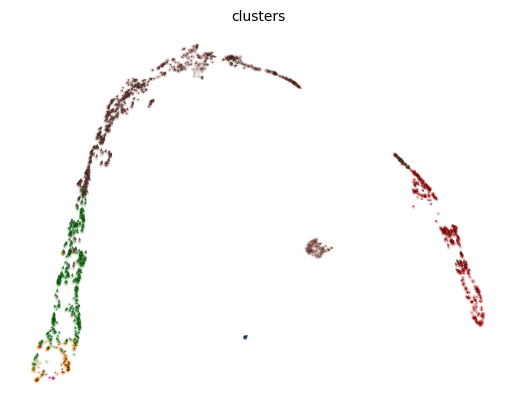

computing velocity embedding
    finished (0:00:00) --> added
    'velocity_tsne', embedded velocity vectors (adata.obsm)


/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/site-packages/scvelo/plotting/utils.py:68: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  return isinstance(c, str) and c in data.obs.keys() and cat(data.obs[c])
/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/site-packages/scvelo/plotting/utils.py:68: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  return isinstance(c, str) and c in data.obs.keys() and cat(data.obs[c])
/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/site-packages/scvelo/plotting/utils.py:68: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  return isinstance(c, str) and c in data.obs.keys() and cat(data.obs[c])
/mnt/vo

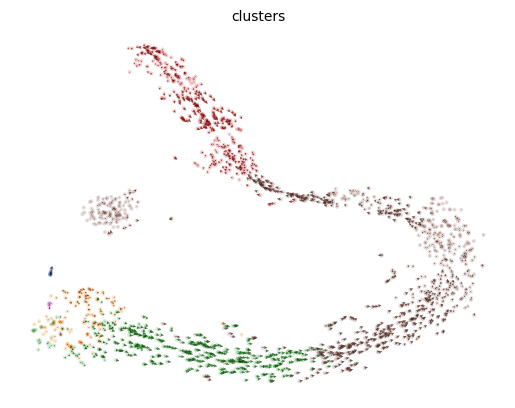

computing velocity embedding
    finished (0:00:00) --> added
    'velocity_pca', embedded velocity vectors (adata.obsm)


In [ ]:
# Dataset 16 - spermatogenesis
# Download: https://www.fmi.ch/groups/gbioinfo/RNAVeloQuant/RNAVeloQuant.html
adata = sc.read("../data/noEmbedding/Spermatogenesis_sce_quantifications_combined.h5ad")
print(adata)
adata.layers['spliced'] = adata.X
adata.layers['unspliced'] = adata.layers['velocyto_unspliced']
adata.obsm['X_umap'] = adata.obsm['UMAP_alevin_spliced_gentrome']
adata.obsm['X_tsne'] = adata.obsm['TSNE_alevin_spliced_gentrome']
adata.uns['cluster_colors'] = ['#0072b2', '#e69f00', '#d55e00', '#f0e442', '#000000', 
                                      '#56b4e9', '#cc79a7']
scvelo.pp.filter_and_normalize(adata, min_shared_counts=20, n_top_genes=2000)
scvelo.pp.moments(adata, n_pcs=30, n_neighbors=30)
scvelo.tl.recover_dynamics(adata, n_jobs=1)
scvelo.tl.velocity(adata, mode='dynamical')
scvelo.tl.velocity_graph(adata) 
scvelo.pl.velocity_embedding(adata, basis='umap')
scvelo.pl.velocity_embedding(adata, basis='tsne')
scvelo.tl.velocity_embedding(adata, basis='pca')
adata.write_h5ad("../data/noEmbedding/spermatogenesis_precomputed.h5ad")


In [ ]:
# Dataset 17 - old brain 
# Download: https://www.fmi.ch/groups/gbioinfo/RNAVeloQuant/RNAVeloQuant.html
adata = sc.read("../data/noEmbedding/OldBrain_sce_quantifications_combined.h5ad")
print(adata)
adata.layers['spliced'] = adata.X
adata.layers['unspliced'] = adata.layers['velocyto_unspliced']
adata.obsm['X_umap'] = adata.obsm['UMAP_alevin_spliced_gentrome']
adata.obsm['X_tsne'] = adata.obsm['TSNE_alevin_spliced_gentrome']
adata.uns['cluster_colors'] = ['#0072b2', '#e69f00', '#d55e00', '#f0e442', '#000000', 
                                '#56b4e9', '#cc79a7']
scvelo.pp.filter_and_normalize(adata, min_shared_counts=20, n_top_genes=2000)
scvelo.pp.moments(adata, n_pcs=30, n_neighbors=30)
scvelo.tl.recover_dynamics(adata, n_jobs=1)
scvelo.tl.velocity(adata, mode='dynamical')
scvelo.tl.velocity_graph(adata) 
scvelo.tl.velocity_embedding(adata, basis='umap')
scvelo.tl.velocity_embedding(adata, basis='tsne')
scvelo.tl.velocity_embedding(adata, basis='pca')
adata.write_h5ad("../data/noEmbedding/old_brain_precomputed.h5ad")

AnnData object with n_obs × n_vars = 1823 × 54143
    obs: 'cell_index', 'clusters_coarse', 'clusters', 'NAME', 'nGene', 'nUMI', 'animal_type', 'cell_type_age'
    uns: 'X_name', 'dataset'
    obsm: 'PCA_alevin_spliced_gentrome', 'TSNE_alevin_spliced_gentrome', 'UMAP_alevin_spliced_gentrome'
    layers: 'alevin_prepref_isocollapse_cdna_introns_decoy_gentrome_spliced', 'alevin_prepref_isocollapse_cdna_introns_decoy_gentrome_unspliced', 'alevin_prepref_isocollapse_cdna_introns_gentrome_spliced', 'alevin_prepref_isocollapse_cdna_introns_gentrome_unspliced', 'alevin_prepref_isoseparate_cdna_introns_decoy_gentrome_spliced', 'alevin_prepref_isoseparate_cdna_introns_decoy_gentrome_unspliced', 'alevin_prepref_isoseparate_cdna_introns_gentrome_spliced', 'alevin_prepref_isoseparate_cdna_introns_gentrome_unspliced', 'alevin_spliced_gentrome_counts', 'alevin_spliced_unspliced_gentrome_spliced', 'alevin_spliced_unspliced_gentrome_unspliced', 'dropest_spliced', 'dropest_unspliced', 'kallisto_bustool

/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/utils.py:705: DeprecationWarning: `log1p` is deprecated since scVelo v0.3.0 and will be removed in a future version. Please use `log1p` from `scanpy.pp` instead.
  log1p(adata)
/tmp/ipykernel_2306945/1712867514.py:11: DeprecationWarning: Automatic neighbor calculation is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors first with Scanpy.
  scvelo.pp.moments(adata, n_pcs=30, n_neighbors=30)
/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/moments.py:71: DeprecationWarning: `neighbors` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors with Scanpy.
  neighbors(
/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/neighbors.py:233: DeprecationWarning: Automatic computation of PCA

computing neighbors
    finished (0:00:00) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
recovering dynamics (using 1/28 cores)
    finished (0:04:53) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
computing velocities
    finished (0:00:02) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/28 cores)
    finished (0:00:03) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:00) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)
computing velocity embedding
    finished (0:00:00) --> added
    'velocity_tsne', embedded velocity vectors (adata.obsm)
computing velocity embedding
    finished (0:00:00) --> adde

In [ ]:
# Dataset 18 - prefrontal cortex
# Download: https://www.fmi.ch/groups/gbioinfo/RNAVeloQuant/RNAVeloQuant.html
adata = sc.read("../data/noEmbedding/PFC_sce_quantifications_combined.h5ad")
print(adata)
adata.layers['spliced'] = adata.X
adata.layers['unspliced'] = adata.layers['velocyto_unspliced']
adata.obsm['X_umap'] = adata.obsm['UMAP_alevin_spliced_gentrome']
adata.obsm['X_tsne'] = adata.obsm['TSNE_alevin_spliced_gentrome']
adata.uns['cluster_colors'] = ['#0072b2', '#e69f00', '#d55e00', '#f0e442', '#000000', 
                                      '#56b4e9', '#cc79a7','#009e73']
scvelo.pp.filter_and_normalize(adata, min_shared_counts=20, n_top_genes=2000)
scvelo.pp.moments(adata, n_pcs=30, n_neighbors=30)
scvelo.tl.recover_dynamics(adata, n_jobs=1)
scvelo.tl.velocity(adata, mode='dynamical')
scvelo.tl.velocity_graph(adata) 
scvelo.tl.velocity_embedding(adata, basis='umap')
scvelo.tl.velocity_embedding(adata, basis='tsne')
scvelo.tl.velocity_embedding(adata, basis='pca')
adata.write_h5ad("../data/noEmbedding/pfc_precomputed.h5ad")

AnnData object with n_obs × n_vars = 1267 × 54144
    obs: 'cell_index', 'clusters_coarse', 'clusters', 'X', 'nGene', 'nUMI', 'percent.mito', 'Sample', 'treatment', 'Period', 'stage', 'DevStage'
    uns: 'X_name', 'dataset'
    obsm: 'PCA_alevin_spliced_gentrome', 'TSNE_alevin_spliced_gentrome', 'UMAP_alevin_spliced_gentrome'
    layers: 'alevin_prepref_isocollapse_cdna_introns_decoy_gentrome_spliced', 'alevin_prepref_isocollapse_cdna_introns_decoy_gentrome_unspliced', 'alevin_prepref_isocollapse_cdna_introns_gentrome_spliced', 'alevin_prepref_isocollapse_cdna_introns_gentrome_unspliced', 'alevin_prepref_isoseparate_cdna_introns_decoy_gentrome_spliced', 'alevin_prepref_isoseparate_cdna_introns_decoy_gentrome_unspliced', 'alevin_prepref_isoseparate_cdna_introns_gentrome_spliced', 'alevin_prepref_isoseparate_cdna_introns_gentrome_unspliced', 'alevin_spliced_gentrome_counts', 'alevin_spliced_unspliced_gentrome_spliced', 'alevin_spliced_unspliced_gentrome_unspliced', 'dropest_spliced', 'dr

/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/utils.py:705: DeprecationWarning: `log1p` is deprecated since scVelo v0.3.0 and will be removed in a future version. Please use `log1p` from `scanpy.pp` instead.
  log1p(adata)
/tmp/ipykernel_2306945/174435051.py:11: DeprecationWarning: Automatic neighbor calculation is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors first with Scanpy.
  scvelo.pp.moments(adata, n_pcs=30, n_neighbors=30)
/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/moments.py:71: DeprecationWarning: `neighbors` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors with Scanpy.
  neighbors(
/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/neighbors.py:233: DeprecationWarning: Automatic computation of PCA 

computing neighbors
    finished (0:00:00) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
recovering dynamics (using 1/28 cores)
    finished (0:03:51) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
computing velocities
    finished (0:00:01) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/28 cores)
    finished (0:00:01) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:00) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)
computing velocity embedding
    finished (0:00:00) --> added
    'velocity_tsne', embedded velocity vectors (adata.obsm)
computing velocity embedding
    finished (0:00:00) --> adde

AnnData object with n_obs × n_vars = 3831 × 9157
    obs: 'well_id', 'batch_id', 'treatment_id', 'log10_gfp', 'rotated_umap1', 'rotated_umap2', 'som_cluster_id', 'monocle_branch_id', 'monocle_pseudotime'
    var: 'gene_symbol'
    uns: 'som_colors'
    obsm: 'X_umap'
    layers: 'spliced_labeled', 'unspliced_labeled', 'spliced_unlabeled', 'unspliced_unlabeled', 'spliced', 'unspliced'
Normalized count data: X, spliced, unspliced.
Extracted 2000 highly variable genes.
Logarithmized X.


/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/site-packages/scvelo/preprocessing/utils.py:705: DeprecationWarning: `log1p` is deprecated since scVelo v0.3.0 and will be removed in a future version. Please use `log1p` from `scanpy.pp` instead.
  log1p(adata)
/tmp/ipykernel_270216/1795674438.py:23: DeprecationWarning: Automatic neighbor calculation is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors first with Scanpy.
  scvelo.pp.moments(adata, n_pcs=30, n_neighbors=30)
/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/site-packages/scvelo/preprocessing/moments.py:71: DeprecationWarning: `neighbors` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors with Scanpy.
  neighbors(
/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/site-packages/scvelo/preprocessing/neighbors.py:233: DeprecationWarning: Automatic computation o

computing neighbors
    finished (0:00:00) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:01) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
recovering dynamics (using 1/28 cores)
    finished (0:01:21) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/28 cores)
    finished (0:00:03) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:00) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/site-packages/scvelo/plotting/utils.py:68: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  return isinstance(c, str) and c in data.obs.keys() and cat(data.obs[c])
/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/site-packages/scvelo/plotting/utils.py:68: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  return isinstance(c, str) and c in data.obs.keys() and cat(data.obs[c])
/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/site-packages/scvelo/plotting/utils.py:68: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  return isinstance(c, str) and c in data.obs.keys() and cat(data.obs[c])
/mnt/vo

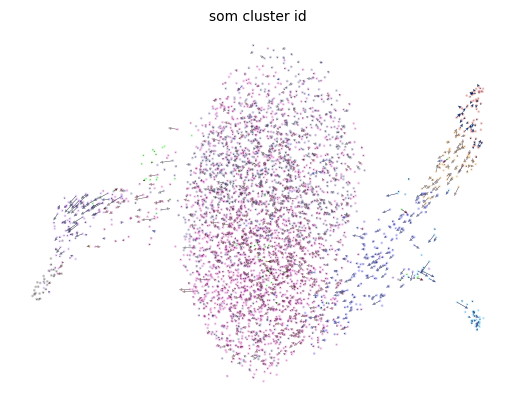

computing velocity embedding
    finished (0:00:00) --> added
    'velocity_tsne', embedded velocity vectors (adata.obsm)


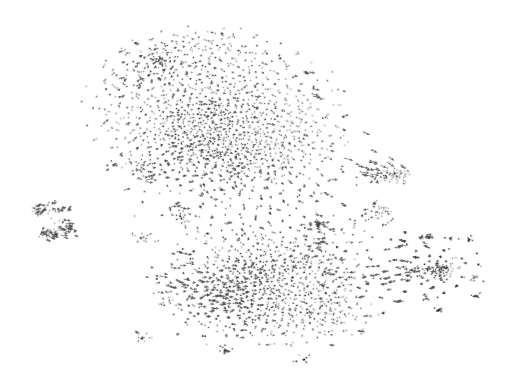

computing velocity embedding
    finished (0:00:00) --> added
    'velocity_pca', embedded velocity vectors (adata.obsm)


In [ ]:
# Dataset 19 - intestinal organoides 
# Download: https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE128365
lsdata = pd.read_csv("../data/GSE128365/SupplementaryData_organoids_labeled_splicedUMI.csv", index_col=(['ID', 'NAME']))  # spliced layer
adata = ad.AnnData(lsdata.values.T)
adata.var_names = lsdata.index.get_level_values('ID')
adata.var['gene_symbol'] = lsdata.index.get_level_values('NAME')
adata.obs_names = lsdata.columns
adata.layers['spliced_labeled'] = adata.X  
adata.layers['unspliced_labeled'] = pd.read_csv("../data/GSE128365/SupplementaryData_organoids_labeled_unsplicedUMI.csv").iloc[:, 2:].values.T # unspliced layer
adata.layers['spliced_unlabeled'] = pd.read_csv("../data/GSE128365/SupplementaryData_organoids_unlabeled_splicedUMI.csv").iloc[:, 2:].values.T # spliced layer
adata.layers['unspliced_unlabeled'] = pd.read_csv("../data/GSE128365/SupplementaryData_organoids_unlabeled_unsplicedUMI.csv").iloc[:, 2:].values.T # unspliced layer
adata.layers['spliced'] = adata.layers['spliced_labeled'] + adata.layers['spliced_unlabeled']
adata.layers['unspliced'] = adata.layers['unspliced_labeled'] + adata.layers['unspliced_unlabeled']
metadata = pd.read_csv("../data/GSE128365/SupplementaryData_organoids_cell_metadata_complete.csv").T
metadata.columns = metadata.iloc[0]
metadata = metadata.drop(metadata.index[0])
adata.obs = metadata
adata.obsm['X_umap'] = np.array((pd.to_numeric(adata.obs['rotated_umap1']), pd.to_numeric(adata.obs['rotated_umap2']))).T
adata.uns['som_colors'] = ["#c50404", "#a93ef6", "#352581", "#e68600", "#c6d103", "#00ff00", "#00AEFE", "#0400ff", "#7000c6", "#d400b8", "#000000"]
print(adata)

# Velocity computing
scvelo.pp.filter_and_normalize(adata, n_top_genes=2000) # taken from Luo Benchmarking paper
scvelo.pp.moments(adata, n_pcs=30, n_neighbors=30)
scvelo.tl.recover_dynamics(adata, n_jobs=1)
scvelo.tl.velocity(adata, mode='dynamical')
scvelo.tl.velocity_graph(adata) 
scvelo.pl.velocity_embedding(adata, basis='umap', color='som_cluster_id', palette='som_colors',)
sc.tl.tsne(adata)
scvelo.pl.velocity_embedding(adata, basis='tsne')
scvelo.tl.velocity_embedding(adata, basis='pca')
adata.write_h5ad("../data/noEmbedding/GSE128365_precomputed.h5ad")


AnnData object with n_obs × n_vars = 16035 × 1987
    obs: 'clusters', 'seurat_clusters', 'timepoint', 'zebrafish_anatomy_ontology_class', 'n_genes', 'n_counts', 'fish', 'Cells_Annotations', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'velocity_self_transition'
    var: 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std', 'gene_count_corr', 'fit_r2', 'fit_alpha', 'fit_beta', 'fit_gamma', 'fit_t_', 'fit_scaling', 'fit_std_u', 'fit_std_s', 'fit_likelihood', 'fit_u0', 'fit_s0', 'fit_pval_steady', 'fit_steady_u', 'fit_steady_s', 'fit_variance', 'fit_alignment_scaling', 'velocity_genes'
    uns: 'Cells_Annotations_colors', 'clusters_colors', 'hvg', 'log1p', 'neighbors', 'pca', 'recover_dynamics', 'seurat_clusters_colors', 'umap', 'velocity_graph', 'velocity_graph_neg', 'velocity_params'
    obsm: 'X_pca', 'X_umap', 'velocity_umap'
    varm: 'PCs', 'loss'
    layers: 'Ms', 'Mu', 'counts', 'fit_t', 'fit_tau', 'fit_tau_', 'matrix', 'spl

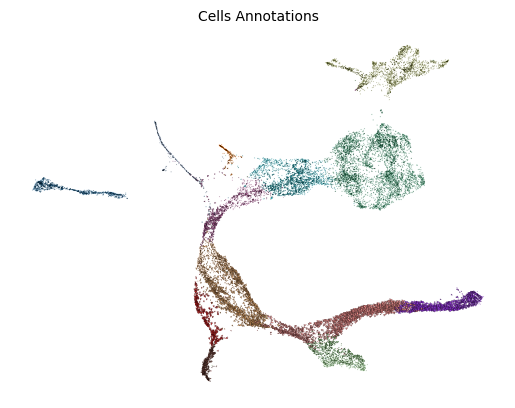

In [ ]:
# Dataset 20: Zebrafish NMP
# Download: https://drive.google.com/drive/folders/1QSrSY1gOhGANtuZ2dIhxeusiPPeAxz6o
adata = sc.read("/mnt/volume/Johanna_Velotest/data/scVelo_dynamical_Jun22.h5ad")
print(adata)
print(adata.obs['Cells_Annotations'].value_counts())
print(adata.uns['Cells_Annotations_colors'])
adata.uns['Cells_Annotations_colors'] = ['#1f77b4', '#ff7f0e', '#279e68', '#d62728', '#aa40fc', '#8c564b', '#e377c2',
                                         '#b5bd61', '#17becf', '#aec7e8', '#ffbb78', '#98df8a', '#ff9896']
scvelo.pl.velocity_embedding(adata, basis='umap', color='Cells_Annotations', palette='Cells_Annotations_colors')
adata.write_h5ad("/mnt/volume/Johanna_Velotest/data/scVelo_dynamical_Jun22_precomputed.h5ad")